## 1. Dataset Import and Shape

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

recipes = pd.read_csv("RAW_recipes.csv")
interactions = pd.read_csv("RAW_interactions.csv")

print("Recipes:", recipes.shape)
print("Interactions:", interactions.shape)

display(recipes.head())
display(interactions.head())

Recipes: (231637, 12)
Interactions: (1132367, 5)


,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8


,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...
3,126440,85009,2010-02-27,5,I made the Mexican topping and took it to bunk...
4,57222,85009,2011-10-01,5,"Made the cheddar bacon topping, adding a sprin..."


## 2. Dataset Features and Data Types

In [28]:

print("RECIPE FEATURES")
print(recipes.info())

print("\nINTERACTION FEATURES")
print(interactions.info())

# Detailed feature overview
display(pd.DataFrame({
    "Feature": recipes.columns,
    "Data Type": recipes.dtypes.astype(str).values
}))

display(pd.DataFrame({
    "Feature": interactions.columns,
    "Data Type": interactions.dtypes.astype(str).values
}))


RECIPE FEATURES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 231637 entries, 0 to 231636
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   name            231636 non-null  object
 1   id              231637 non-null  int64 
 2   minutes         231637 non-null  int64 
 3   contributor_id  231637 non-null  int64 
 4   submitted       231637 non-null  object
 5   tags            231637 non-null  object
 6   nutrition       231637 non-null  object
 7   n_steps         231637 non-null  int64 
 8   steps           231637 non-null  object
 9   description     226658 non-null  object
 10  ingredients     231637 non-null  object
 11  n_ingredients   231637 non-null  int64 
dtypes: int64(5), object(7)
memory usage: 21.2+ MB
None

INTERACTION FEATURES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1132367 entries, 0 to 1132366
Data columns (total 5 columns):
 #   Column     Non-Null Count    Dtype 
---  ------ 

,Feature,Data Type
0,name,object
1,id,int64
2,minutes,int64
3,contributor_id,int64
4,submitted,object
5,tags,object
6,nutrition,object
7,n_steps,int64
8,steps,object
9,description,object


,Feature,Data Type
0,user_id,int64
1,recipe_id,int64
2,date,object
3,rating,int64
4,review,object


## 3. Missing Value Analysis

In [24]:

recipe_missing = pd.DataFrame({
    "Missing Count": recipes.isnull().sum(),
})

interaction_missing = pd.DataFrame({
    "Missing Count": interactions.isnull().sum(),
})

print("Missing values in recipes:")
display(recipe_missing)

print("Missing values in interactions:")
display(interaction_missing)


Missing values in recipes:


,Missing Count
name,1
id,0
minutes,0
contributor_id,0
submitted,0
tags,0
nutrition,0
n_steps,0
steps,0
description,4979


Missing values in interactions:


,Missing Count
user_id,0
recipe_id,0
date,0
rating,0
review,169


## 4. Duplicate Record Analysis

In [4]:

print("Duplicate recipe rows:", recipes.duplicated().sum())

print("Duplicate recipe IDs:", recipes["id"].duplicated().sum())

print("Duplicate interaction rows:", interactions.duplicated().sum())

print("Repeated user-recipe pairs:",
      interactions.duplicated(
          subset=["user_id", "recipe_id"]
      ).sum())


Duplicate recipe rows: 0
Duplicate recipe IDs: 0
Duplicate interaction rows: 0
Repeated user-recipe pairs: 0


## 5. Rating Statistics and Distribution

Rating statistics:


count   1132367.00
mean          4.41
std           1.26
min           0.00
25%           4.00
50%           5.00
75%           5.00
max           5.00
Name: rating, dtype: float64

Rating distribution:
rating
0     60847
1     12818
2     14123
3     40855
4    187360
5    816364
Name: count, dtype: int64


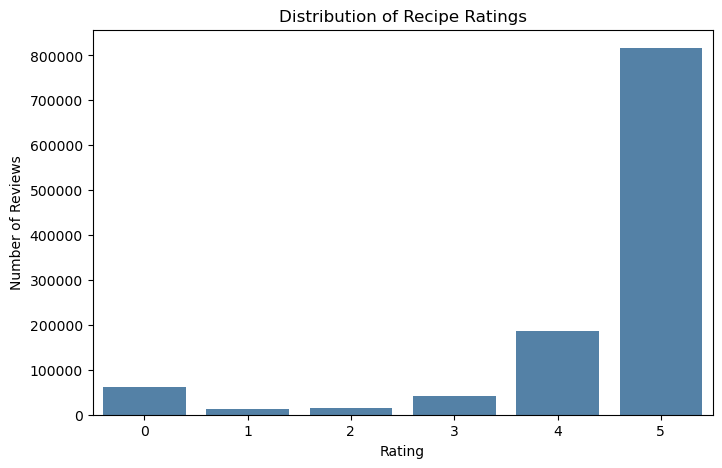

In [26]:
pd.set_option("display.float_format", "{:.2f}".format)
print("Rating statistics:")
display(interactions["rating"].describe())

print("Rating distribution:")
print(interactions["rating"].value_counts().sort_index())

plt.figure(figsize=(8, 5))

sns.countplot(
    data=interactions,
    x="rating",
    color="steelblue"
)

plt.title("Distribution of Recipe Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()


## 6. User and Recipe Interaction Analysis

In [6]:

num_users = interactions["user_id"].nunique()
num_recipes = interactions["recipe_id"].nunique()
num_interactions = len(interactions)

print("Unique users:", num_users)
print("Unique rated recipes:", num_recipes)
print("Total interactions:", num_interactions)

# Reviews per user
ratings_per_user = interactions.groupby("user_id")["recipe_id"].nunique()

# Reviews per recipe
ratings_per_recipe = interactions.groupby("recipe_id")["user_id"].nunique()

print("\nRatings per user:")
display(ratings_per_user.describe())

print("\nRatings per recipe:")
display(ratings_per_recipe.describe())


Unique users: 226570
Unique rated recipes: 231637
Total interactions: 1132367

Ratings per user:


count    226570.000000
mean          4.997868
std          49.663111
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        7671.000000
Name: recipe_id, dtype: float64


Ratings per recipe:


count    231637.000000
mean          4.888541
std          17.532481
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max        1613.000000
Name: user_id, dtype: float64

## 7. Dataset Merge and Feature Overview

In [9]:

merged = interactions.merge(
    recipes,
    left_on="recipe_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

print("Merged dataset shape:", merged.shape)

display(merged[
    [
        "user_id",
        "recipe_id",
        "name",
        "rating",
        "minutes",
        "ingredients",
        "n_ingredients"
    ]
].head())

print("Interactions without matching recipes:",
      merged["id"].isna().sum())


Merged dataset shape: (1132367, 17)


,user_id,recipe_id,name,rating,minutes,ingredients,n_ingredients
0,38094,40893,white bean green chile pepper soup,4,495,"['great northern beans', 'yellow onion', 'dice...",9
1,1293707,40893,white bean green chile pepper soup,5,495,"['great northern beans', 'yellow onion', 'dice...",9
2,8937,44394,devilicious cookie cake delights,4,20,"[""devil's food cake mix"", 'vegetable oil', 'eg...",4
3,126440,85009,baked potato toppings,5,10,"['mayonnaise', 'salsa', 'cheddar cheese', 'ref...",13
4,57222,85009,baked potato toppings,5,10,"['mayonnaise', 'salsa', 'cheddar cheese', 'ref...",13


Interactions without matching recipes: 0
